# COMP6019 — Student 2: Spatiotemporal Smoke Forecasting
**Data-driven wildfire smoke impact prediction & air-quality early-warning system for Australia**

**Student 2 research question:** *Can current fire activity, weather conditions and historical air-quality observations
predict **where** and **when** elevated PM2.5 will occur (6 / 12 / 24 / 48 hours ahead)?*



**Validation rule (from the project brief):** never a random split. We use temporal validation, event-based validation
(Black Summer 2019-20) and spatial validation (leave-one-station-out).

## 0. Setup & configuration


In [1]:
import os, sys, re, glob, math, time, json, warnings, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

def _ensure(pkg, mod=None):
    try:
        __import__(mod or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
for _p in ["xlrd", "openpyxl", "pyarrow", "lightgbm", "xgboost", "scikit-learn"]:
    _ensure(_p, "sklearn" if _p == "scikit-learn" else None)

import matplotlib
IN_COLAB = "google.colab" in sys.modules
if not IN_COLAB and not os.environ.get("DISPLAY") and "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ---------------- paths ----------------
if IN_COLAB:
    # Use the file uploaded in the Colab Files panel (/content/RAW.zip) first; Google Drive is only a fallback.
    import zipfile
    RAW_DIR  = Path("/content/RAW")
    WORK_DIR = Path("/content/work")
    if not RAW_DIR.exists():
        zips = [Path("/content/RAW.zip"), Path("/content/drive/MyDrive/COMP6019/RAW.zip")]
        if not any(z.exists() for z in zips[:1]) and Path("/content/drive/MyDrive").exists() is False:
            try:
                from google.colab import drive
                drive.mount("/content/drive")
            except Exception as e:
                print("Drive not mounted:", e)
        found = next((z for z in zips if z.exists()), None)
        if found is None:
            raise FileNotFoundError("Upload RAW.zip in the Colab Files panel (it must appear as /content/RAW.zip) and run this cell again.")
        with zipfile.ZipFile(found) as zf: zf.extractall("/content")
        print("Unzipped", found, "->", RAW_DIR)
else:
    RAW_DIR  = Path(os.environ.get("RAW_DIR", "./RAW"))
    WORK_DIR = Path(os.environ.get("WORK_DIR", "./work"))
DATA_DIR = WORK_DIR / "data"; FS_DIR = DATA_DIR / "feature_store"; HS_CACHE = DATA_DIR / "hotspot_parquet"
OUT_DIR  = WORK_DIR / "results_student2"; FIG_DIR = OUT_DIR / "figures"
for d in [DATA_DIR, FS_DIR, HS_CACHE, OUT_DIR, FIG_DIR]: d.mkdir(parents=True, exist_ok=True)

# ---------------- study configuration ----------------
QUICK_MODE = os.environ.get("QUICK_MODE", "0") == "1"
SKIP_DL    = os.environ.get("SKIP_DL", "0") == "1"      # skip neural networks (e.g. no GPU)
DL_EPOCHS  = int(os.environ.get("DL_EPOCHS", "14"))      # max training passes per network
DL_STRIDE  = int(os.environ.get("DL_STRIDE", "1"))      # use every k-th training sample (1 = all; >1 only for a quick CPU run)
FAST_GBM   = os.environ.get("FAST_GBM", "0") == "1"     # LightGBM variants only (skip XGBoost) to save time   # True = tiny/fast run for debugging only
SEED       = 42
STATIONS   = ["Richmond", "Liverpool", "Wollongong", "Wyong", "Newcastle", "Earlwood"]
HORIZONS   = [6, 12, 24, 48]                 # forecast lead times in hours (AQ data are hourly, so all are feasible)
UTC_OFFSET = 10                              # NSW AQ data are in AEST (UTC+10, no daylight saving); DEA hotspots are UTC
GRID = pd.date_range("2016-01-01 01:00", "2026-01-01 00:00", freq="h")   # hour-ENDING timestamps; 24:00 -> next-day 00:00
T = len(GRID)
RADII = [50, 100, 200, 500]                  # km radii for fire features
SENSORS = ["MODIS"]                          # WHY: only MODIS (Terra/Aqua) exists in ALL years; VIIRS/AHI appear from 2019 and
                                             # would inflate fire counts ~20x in the test years (see sensor audit below)
MIN_CONF = 30                                # MODIS detection confidence (0-100); drop very low-confidence detections
MAX_FIRE_KM = 500

# temporal validation design (no random splits)
VAL_START   = pd.Timestamp("2019-01-01")     # train = before this
TEST_START  = pd.Timestamp("2019-10-01")     # val = [VAL_START, TEST_START);  test = from here on
BS_START, BS_END = pd.Timestamp("2019-11-01"), pd.Timestamp("2020-02-29 23:00")   # Black Summer core window
POST_START  = pd.Timestamp("2020-04-01")     # "normal" later years
EXCEED = [25, 50]                            # ug/m3 thresholds (NSW AQC: >=25 'fair/elevated', >=50 'poor')
np.random.seed(SEED)
print("RAW_DIR :", RAW_DIR.resolve(), "| exists:", RAW_DIR.exists())
print("WORK_DIR:", WORK_DIR.resolve(), "| QUICK_MODE:", QUICK_MODE)

# plotting style (validated colour-blind-safe categorical palette, thin marks, recessive grid)
PAL = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#6250d6", "yellow": "#eda100",
       "magenta": "#e87ba4", "green": "#008300", "grey": "#6b6a66", "red": "#e34948"}
MODEL_STYLE = {   # fixed colour/marker per model so colours never change between figures
    "Persistence": (PAL["grey"], "o", "--"), "Climatology": ("#a8a7a0", "s", ":"), "Ridge": (PAL["yellow"], "^", "-"),
    "LightGBM": (PAL["blue"], "o", "-"), "LightGBM-resid": (PAL["violet"], "D", "-"), "LightGBM-logratio": (PAL["magenta"], "v", "-"),
    "XGBoost": (PAL["aqua"], "s", "-"), "GRU": (PAL["orange"], "P", "-"), "LSTM": (PAL["red"], "X", "-"), "TCN": (PAL["green"], "*", "-"),
}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8984", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.7,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 9.5, "legend.frameon": False,
                     "lines.linewidth": 1.6, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png"); plt.show(); plt.close()

Unzipped /content/RAW.zip -> /content/RAW
RAW_DIR : /content/RAW | exists: True
WORK_DIR: /content/work | QUICK_MODE: False


## 1. Station metadata
**Why:** fire distance/bearing and the neighbour-station (smoke propagation) features need station coordinates.
`Stations.csv` has a hidden BOM character and `"Earlwood "` has a trailing space — both would break joins, so we clean them.

In [2]:
st = pd.read_csv(RAW_DIR / "Stations.csv", encoding="utf-8-sig")
st.columns = [c.strip().lower() for c in st.columns]
st["station"] = st["station"].astype(str).str.strip()
st = st.set_index("station").loc[STATIONS]
st

,latitude,longitude
station,,
Richmond,-33.618,150.751
Liverpool,-33.920,150.924
Wollongong,-34.430,150.880
Wyong,-33.149,151.488
Newcastle,-32.928,151.782
Earlwood,-33.910,151.110


## 2. Clean the air-quality data (6 stations × 10 years)  — *shared pipeline*


In [3]:
VAR_PATTERNS = {"Wind_Direction": "WDR", "TEMP": "TEMP", "Wind_speed": "WSP", "PM25": "PM2.5", "HUMIDITY": "HUMID", "RAINFALL": "RAIN"}

def read_year_file(path):
    raw = pd.read_excel(path, header=None)
    hdr = raw.index[raw.iloc[:, 0].astype(str).str.strip().eq("Date")][0]      # header row (robust to extra title rows)
    cols = raw.iloc[hdr].astype(str).str.strip().tolist()
    body = raw.iloc[hdr + 1:].copy(); body.columns = cols
    out = pd.DataFrame({"Date": body["Date"].astype(str).str.strip(), "Time": body["Time"].astype(str).str.strip()})
    for std, key in VAR_PATTERNS.items():
        m = [c for c in cols if re.search(r"\b" + re.escape(key) + r"\b", c) and "rolling" not in c.lower() and "1h average" in c]
        out[std] = pd.to_numeric(body[m[0]], errors="coerce") if m else np.nan   # Earlwood: RAIN absent -> NaN
    return out

def load_station_raw(station):
    files = sorted(RAW_DIR.rglob(f"{station}-20??.xls"))
    assert files, f"No raw files found for {station} under {RAW_DIR}"
    d = pd.concat([read_year_file(f) for f in files], ignore_index=True)
    t = d["Time"].str.slice(0, 5)
    is24 = t.str.startswith("24")
    t = t.where(~is24, "00:" + t.str.slice(3, 5))
    dt = pd.to_datetime(d["Date"] + " " + t, format="%d/%m/%Y %H:%M", errors="coerce") + pd.to_timedelta(is24.astype(int), unit="D")
    d.insert(0, "datetime", dt)
    return d.drop(columns=["Date", "Time"]).dropna(subset=["datetime"])

def clean_station(raw, station):
    s = raw.set_index("datetime").sort_index()
    s = s[~s.index.duplicated(keep="first")].reindex(GRID)            # complete hourly grid (gaps become explicit NaN rows)
    pm = s["PM25"].copy()
    pm[pm <= -9.9] = np.nan; pm = pm.clip(lower=0); pm[pm > 1000] = np.nan
    temp = s["TEMP"].where(s["TEMP"].between(-15, 55))
    hum  = s["HUMIDITY"].clip(0, 100)
    ws   = s["Wind_speed"].where(s["Wind_speed"].between(0, 60))
    wd   = (s["Wind_Direction"].where(s["Wind_Direction"].between(0, 360))) % 360
    rain = s["RAINFALL"].where(s["RAINFALL"] >= 0)
    o = pd.DataFrame(index=GRID); o.index.name = "datetime"
    o["station"] = station
    o["PM25"]   = pm                         # OBSERVED (used for targets/evaluation only)
    o["PM25_f"] = pm.ffill(limit=3)          # causal gap-filled series (used for features)
    o["TEMP"] = temp.ffill(limit=6); o["HUMIDITY"] = hum.ffill(limit=6); o["Wind_speed"] = ws.ffill(limit=6)
    o["Wind_Direction"] = wd.ffill(limit=3)
    th = np.deg2rad(o["Wind_Direction"])     # meteorological convention: direction wind blows FROM
    o["wind_u"] = -o["Wind_speed"] * np.sin(th)   # eastward component of the flow
    o["wind_v"] = -o["Wind_speed"] * np.cos(th)   # northward component of the flow
    o["rainfall_missing"] = rain.isna().astype("int8")
    o["Rainfall"] = rain.fillna(0)
    return o

t0 = time.time()
aq = {}
for s in STATIONS:
    aq[s] = clean_station(load_station_raw(s), s)
    print(f"{s:11s} rows={len(aq[s]):6d}  PM2.5 observed={aq[s]['PM25'].notna().mean()*100:5.1f}%")
AQ_ALL = pd.concat(aq.values()).reset_index()
AQ_ALL.to_parquet(DATA_DIR / "air_quality_clean.parquet")
print(f"saved air_quality_clean.parquet  ({time.time()-t0:.0f}s)")

Richmond    rows= 87672  PM2.5 observed= 91.7%
Liverpool   rows= 87672  PM2.5 observed= 95.1%
Wollongong  rows= 87672  PM2.5 observed= 91.8%
Wyong       rows= 87672  PM2.5 observed= 94.6%
Newcastle   rows= 87672  PM2.5 observed= 94.7%
Earlwood    rows= 87672  PM2.5 observed= 96.6%
saved air_quality_clean.parquet  (30s)


### 2b. Data-quality audit: how much PM2.5 do we really have?


year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
station,,,,,,,,,,
Richmond,92.3,91.0,92.0,84.0,90.0,95.8,94.3,93.2,87.3,97.2
Liverpool,91.5,91.4,95.5,94.9,95.6,98.5,98.6,98.3,97.7,89.3
Wollongong,88.1,90.0,92.4,85.3,85.3,97.3,98.1,96.3,91.9,93.3
Wyong,94.8,95.0,90.2,90.4,95.5,98.1,94.8,93.5,97.3,96.6
Newcastle,93.7,96.7,97.3,96.8,73.9,96.0,98.4,97.3,98.6,98.5
Earlwood,94.8,90.1,96.5,95.8,97.0,97.5,98.5,97.7,99.0,98.8


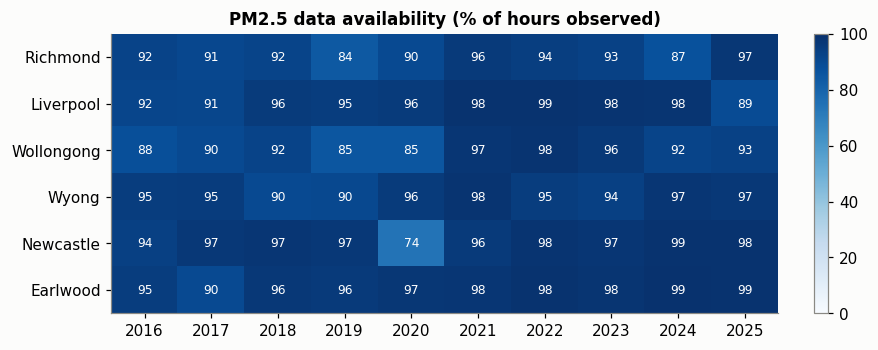

In [4]:
avail = (AQ_ALL[AQ_ALL["datetime"] < "2026-01-01"].assign(year=lambda d: d["datetime"].dt.year).groupby(["station", "year"])["PM25"].apply(lambda x: x.notna().mean() * 100)
         .unstack().loc[STATIONS].round(1))
display(avail) if "ipykernel" in sys.modules else print(avail)
fig, ax = plt.subplots(figsize=(8.5, 3.3))
im = ax.imshow(avail.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(avail.shape[1])); ax.set_xticklabels(avail.columns); ax.set_yticks(range(len(avail))); ax.set_yticklabels(avail.index)
for i in range(avail.shape[0]):
    for j in range(avail.shape[1]):
        ax.text(j, i, f"{avail.values[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if avail.values[i, j] > 60 else "#222")
ax.grid(False); ax.set_title("PM2.5 data availability (% of hours observed)"); plt.colorbar(im, ax=ax, fraction=0.03)
savefig("01_pm25_availability")
avail.to_csv(OUT_DIR / "pm25_availability_pct.csv")

## 3. Clean the fire (hotspot) data and **audit it before trusting it**  — *shared pipeline*
Reading 13 large Excel files is slow, so each is cached as Parquet in `WORK_DIR`.

**Three problems were found in these files — the code detects and handles all three:**
1. **Timezone:** hotspot `datetime` is **UTC**; AQ data are **AEST (UTC+10)** → add 10 h, and assign each detection to the hour-ending slot it falls in (otherwise fires are mis-aligned by 10 h).
2. **Duplicates / overlapping files:** the 2019 files overlap and DEA lists some detections twice → drop duplicates.
3. **Sensor mix & export cap:** MODIS exists in every year, but VIIRS and Himawari-AHI appear from 2019 (hundreds of thousands of rows vs ~10 k/yr before),
   and some files stop at exactly **300,000 rows (the DEA export limit)** which silently truncates the period. We therefore (a) keep **MODIS only** so fire features
   mean the same thing in training and test years, and (b) detect time gaps and set fire features to **missing (NaN)** there instead of wrongly saying "no fires".

In [5]:
HS_COLS = ["latitude", "longitude", "temp_kelvin", "power", "confidence", "datetime", "satellite", "sensor"]
hs_files = sorted(RAW_DIR.rglob("DEA_Hotspot_*.xlsx"))
assert hs_files, "No DEA_Hotspot_*.xlsx files found"
parts, file_meta = [], []
t0 = time.time()
for f in hs_files:
    cache = HS_CACHE / (f.stem + ".parquet")
    if cache.exists():
        d = pd.read_parquet(cache, columns=HS_COLS)
    else:
        d = pd.read_excel(f, usecols=HS_COLS); d["datetime"] = pd.to_datetime(d["datetime"]); d.to_parquet(cache)
    d["datetime"] = pd.to_datetime(d["datetime"])
    file_meta.append({"file": f.name, "rows": len(d), "first_utc": d["datetime"].min(), "last_utc": d["datetime"].max(),
                      "hit_300k_cap": len(d) == 300000})
    parts.append(d)
print(f"hotspot files read in {time.time()-t0:.0f}s")
HS_RAW = pd.concat(parts, ignore_index=True)
file_meta = pd.DataFrame(file_meta).sort_values("first_utc")
display(file_meta) if "ipykernel" in sys.modules else print(file_meta.to_string())

hotspot files read in 699s


,file,rows,first_utc,last_utc,hit_300k_cap
0,DEA_Hotspot_2016.xlsx,5203,2016-01-02 03:56:10,2016-09-04 23:44:20,False
1,DEA_Hotspot_2017.xlsx,11521,2017-03-06 00:42:30,2017-12-30 12:36:24,False
2,DEA_Hotspot_2018.xlsx,15133,2018-01-02 03:41:53,2018-12-31 00:43:45,False
3,DEA_Hotspot_2019_01_11.xlsx,300000,2019-01-02 00:31:59,2019-11-15 05:50:00,True
4,DEA_Hotspot_2019_11_12.xlsx,300000,2019-11-15 05:50:00,2019-12-10 04:11:34,True
5,DEA_Hotspot_2020.xlsx,255285,2020-01-01 19:10:00,2020-12-31 14:42:14,False
6,DEA_Hotspot_2021.xlsx,218464,2021-01-02 04:26:51,2021-12-31 15:38:39,False
7,DEA_Hotspot_2022.xlsx,152619,2022-01-02 03:40:52,2022-12-31 15:46:44,False
8,DEA_Hotspot_2023_01-08.xlsx,300000,2023-01-01 22:58:18,2023-08-11 03:06:31,True
9,DEA_Hotspot_2023_08-012.xlsx,245401,2023-08-11 03:06:31,2023-12-31 15:51:56,False


In [6]:
# --- sensor audit: detections per year per sensor ---
sens = HS_RAW.assign(year=HS_RAW["datetime"].dt.year).groupby(["year", "sensor"]).size().unstack(fill_value=0)
print("Detections per year and sensor (why we keep MODIS only):"); print(sens)
sens.to_csv(OUT_DIR / "hotspot_sensor_audit.csv")

# --- coverage audit: union of file time-windows, gaps longer than 3 days ---
win = file_meta[["first_utc", "last_utc"]].sort_values("first_utc").values
merged = []
for a, b in win:
    if merged and a <= merged[-1][1] + pd.Timedelta(days=3): merged[-1][1] = max(merged[-1][1], b)
    else: merged.append([a, b])
gaps = []
cur = pd.Timestamp("2016-01-01") - pd.Timedelta(hours=UTC_OFFSET)
for a, b in merged:
    if a - cur > pd.Timedelta(days=3): gaps.append((cur, a))
    cur = max(cur, b)
end_utc = pd.Timestamp("2025-12-31 14:00")
if end_utc - cur > pd.Timedelta(days=3): gaps.append((cur, end_utc))
GAPS = pd.DataFrame(gaps, columns=["gap_start_utc", "gap_end_utc"]); GAPS["days"] = (GAPS["gap_end_utc"] - GAPS["gap_start_utc"]).dt.days
print("\n*** HOTSPOT COVERAGE GAPS (no fire data in these periods) ***"); print(GAPS.to_string() if len(GAPS) else "none")
fm = file_meta.reset_index(drop=True)
for i, r in fm[fm.hit_300k_cap].iterrows():
    nxt = fm.loc[i + 1, "first_utc"] if i + 1 < len(fm) else None
    if nxt is None or nxt > r["last_utc"] + pd.Timedelta(days=1):
        print(f"WARNING: {r['file']} has exactly 300,000 rows (DEA export cap) and the next file does not continue from {r['last_utc']} UTC "
              f"-> data after that is MISSING. Re-export that period from DEA in smaller date chunks.")
    else:
        print(f"OK: {r['file']} hit the 300,000-row cap but the next file starts at {nxt} UTC, so the period is continuous.")
GAPS.to_csv(OUT_DIR / "hotspot_coverage_gaps.csv", index=False)

Detections per year and sensor (why we keep MODIS only):
sensor     AHI  MODIS   VIIRS
year                         
2016         0   5203       0
2017         0  11521       0
2018         0  15133       0
2019    278555  61104  260341
2020     84482  21510  149293
2021         0  47104  171360
2022      1878  20711  130030
2023    198008  31835  315558
2024     90279  19042  155245
2025    103511  18573  271120

*** HOTSPOT COVERAGE GAPS (no fire data in these periods) ***
        gap_start_utc         gap_end_utc  days
0 2016-09-04 23:44:20 2017-03-06 00:42:30   182
1 2019-12-10 04:11:34 2020-01-01 19:10:00    22
OK: DEA_Hotspot_2019_01_11.xlsx hit the 300,000-row cap but the next file starts at 2019-11-15 05:50:00 UTC, so the period is continuous.
OK: DEA_Hotspot_2023_01-08.xlsx hit the 300,000-row cap but the next file starts at 2023-08-11 03:06:31 UTC, so the period is continuous.
OK: DEA_Hotspot_2025_01_09.xlsx hit the 300,000-row cap but the next file starts at 2025-09-24 07:08

In [7]:
# --- build the clean hotspot table ---
hs = HS_RAW[HS_RAW["sensor"].isin(SENSORS)].copy()
hs = hs.dropna(subset=["latitude", "longitude", "power", "datetime"])
hs = hs[hs["latitude"].between(-45, -9) & hs["longitude"].between(110, 160)]
hs = hs[hs["confidence"] >= MIN_CONF]
hs = hs.drop_duplicates(subset=["latitude", "longitude", "datetime", "satellite", "sensor"])
hs["local"] = hs["datetime"] + pd.Timedelta(hours=UTC_OFFSET)                  # UTC -> AEST
hs["hour_end"] = hs["local"].dt.ceil("h")                                       # same hour-ending convention as AQ
hs["hidx"] = ((hs["hour_end"] - GRID[0]) // pd.Timedelta(hours=1)).astype("int64")
hs = hs[(hs["hidx"] >= 0) & (hs["hidx"] < T)].reset_index(drop=True)
hs["power"] = hs["power"].clip(lower=0)
hs.to_parquet(DATA_DIR / "hotspots_clean.parquet")
print(f"kept {len(hs):,} of {len(HS_RAW):,} detections  (sensor={SENSORS}, confidence>={MIN_CONF}, de-duplicated)")
print(hs.groupby(hs["local"].dt.year).size().rename("MODIS detections kept").to_frame().T)

# hours covered by hotspot data (local time). Fire features are NaN outside coverage (+48 h after a gap, because trailing windows)
ok = np.zeros(T, bool)
for a, b in merged:
    la, lb = a + pd.Timedelta(hours=UTC_OFFSET), b + pd.Timedelta(hours=UTC_OFFSET)
    ok |= (GRID >= la) & (GRID <= lb)
gap_recent = pd.Series(~ok).astype(float).rolling(48, min_periods=1).max().values.astype(bool)
print(f"hours with fire data unavailable: {gap_recent.mean()*100:.1f}% of grid")

kept 220,192 of 2,461,396 detections  (sensor=['MODIS'], confidence>=30, de-duplicated)
local                  2016   2017   2018   2019   2020   2021   2022   2023  \
MODIS detections kept  5069  11027  14446  56783  19623  29481  15506  31082   

local                   2024   2025  
MODIS detections kept  18824  18351  
hours with fire data unavailable: 5.8% of grid


## 4. Feature store  — *shared; Student 2 owns the `nbr_*` propagation features*
**Why each feature group exists**
* **PM2.5 memory** (`pm25_lag*`, rolling mean/max): previous PM2.5 is the strongest predictor of future PM2.5.
* **Fire exposure** — *not* a plain fire count (project brief): FRP summed in 50/100/200/500 km rings, nearest-fire distance,
  `fire_expo = Σ FRP/d²` (closer & stronger fires matter more) and **`upwind_expo = Σ FRP·alignment/d²`** where
  `alignment = max(0, cos(bearing_to_fire − wind_from_direction))` (a fire *upwind* of the station counts, one downwind does not).
  All fire quantities are trailing sums (6/12/24/48 h) because satellites pass only a few times per day.
* **Weather**: temperature, humidity, wind speed, wind as u/v components (a circular angle is a bad model input), rainfall.
* **Time**: hour, month, season (+ sin/cos so 23:00 is "close" to 00:00).
* **Neighbour-station (smoke propagation) features — Student 2 task 1–3:** PM2.5 at the *other* five stations 1/3/6 h ago, as a mean, a max and an
  **upwind-weighted** mean (weights = alignment of the neighbour's bearing with the local wind). If smoke travels between locations, upwind neighbours see it first.
* **Targets** `y_6h … y_48h` = observed PM2.5 at t+h.

In [8]:
def haversine_bearing(lat0, lon0, lat, lon):
    R = 6371.0088
    p1, p2 = np.radians(lat0), np.radians(lat)
    dphi, dl = p2 - p1, np.radians(lon - lon0)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    d = 2 * R * np.arcsin(np.sqrt(a))
    y = np.sin(dl) * np.cos(p2); x = np.cos(p1) * np.sin(p2) - np.sin(p1) * np.cos(p2) * np.cos(dl)
    return d, (np.degrees(np.arctan2(y, x)) + 360) % 360          # distance km, bearing station->point (deg from north)

def roll_sum(a, w): return pd.Series(a).rolling(w, min_periods=1).sum().values

def fire_features(lat0, lon0, wd_from):
    """hourly fire features for one station. wd_from = wind-FROM direction (deg) on GRID (NaN allowed)."""
    d, brg = haversine_bearing(lat0, lon0, hs["latitude"].values, hs["longitude"].values)
    m = d <= MAX_FIRE_KM
    d, brg = d[m], brg[m]; frp = hs["power"].values[m]; idx = hs["hidx"].values[m]
    dd = np.maximum(d, 5.0)                                          # floor 5 km so a fire next door does not explode 1/d^2
    wd_at = wd_from[idx]
    align = np.where(np.isnan(wd_at), 0.0, np.maximum(0.0, np.cos(np.radians(brg - wd_at))))
    cnt, frps = {}, {}
    for R in RADII:
        mm = d <= R
        cnt[R]  = np.bincount(idx[mm], minlength=T)[:T].astype(float)
        frps[R] = np.bincount(idx[mm], weights=frp[mm], minlength=T)[:T]
    expo = np.bincount(idx, weights=frp / dd ** 2, minlength=T)[:T]
    upx  = np.bincount(idx, weights=frp * align / dd ** 2, minlength=T)[:T]
    m200, m500 = d <= 200, d <= 500
    upf200 = np.bincount(idx[m200], weights=(frp * align)[m200], minlength=T)[:T]
    upf500 = np.bincount(idx[m500], weights=(frp * align)[m500], minlength=T)[:T]
    near = np.full(T, np.inf); np.minimum.at(near, idx, d); near[np.isinf(near)] = np.nan
    F = {}
    for R in RADII:
        F[f"fires_{R}km_24h"] = roll_sum(cnt[R], 24); F[f"frp_{R}km_24h"] = roll_sum(frps[R], 24)
    for w in (6, 12, 48): F[f"frp_200km_{w}h"] = roll_sum(frps[200], w)
    F["fires_200km_48h"] = roll_sum(cnt[200], 48)
    F["fire_expo_24h"] = roll_sum(expo, 24); F["upwind_expo_6h"] = roll_sum(upx, 6); F["upwind_expo_24h"] = roll_sum(upx, 24)
    F["upwind_frp_200km_24h"] = roll_sum(upf200, 24); F["upwind_frp_500km_24h"] = roll_sum(upf500, 24)
    nf = pd.Series(near).rolling(24, min_periods=1).min().values
    F["nearest_fire_km_24h"] = np.where(np.isnan(nf), MAX_FIRE_KM + 100, nf)      # 600 = "no fire within 500 km"
    has = cnt[200] > 0
    last = np.maximum.accumulate(np.where(has, np.arange(T), -1))
    F["hours_since_fire_200km"] = np.minimum(np.where(last >= 0, np.arange(T) - last, 168), 168).astype(float)
    F["fire_hours_7d_200km"] = roll_sum(has.astype(float), 168)                    # duration/persistence of fire activity
    return pd.DataFrame(F, index=GRID)

FIRE_COLS = None
fs = {}
t0 = time.time()
for s in STATIONS:
    base = aq[s].copy()
    f = fire_features(st.loc[s, "latitude"], st.loc[s, "longitude"], base["Wind_Direction"].values)
    f[gap_recent] = np.nan                                                          # unknown, NOT zero, where fire data are missing
    FIRE_COLS = list(f.columns)
    base = pd.concat([base, f], axis=1)
    base["fire_missing"] = gap_recent.astype("int8")
    fs[s] = base
    print(f"{s:11s} fire features done ({time.time()-t0:.0f}s)")

Richmond    fire features done (0s)
Liverpool   fire features done (0s)
Wollongong  fire features done (1s)
Wyong       fire features done (1s)
Newcastle   fire features done (1s)
Earlwood    fire features done (1s)


In [9]:
# ---- PM2.5 memory, time features, targets (per station, on the complete hourly grid so shift() = real hours) ----
LAGS = [1, 2, 3, 6, 12, 24, 48]
for s in STATIONS:
    b = fs[s]; p = b["PM25_f"]
    b["pm25_now"] = p
    for L in LAGS: b[f"pm25_lag{L}"] = p.shift(L)
    for w in (6, 12, 24): b[f"pm25_mean_{w}h"] = p.rolling(w, min_periods=max(2, w // 2)).mean()
    b["pm25_max_24h"] = p.rolling(24, min_periods=12).max()
    b["pm25_std_24h"] = p.rolling(24, min_periods=12).std()
    b["pm25_diff_3h"] = p - p.shift(3)
    b["log_pm25"] = np.log1p(p)
    for h in HORIZONS: b[f"y_{h}h"] = b["PM25"].shift(-h)                          # TARGET: observed PM2.5 h hours ahead
    b["hour"] = b.index.hour; b["month"] = b.index.month
    b["season"] = b["month"].map({12: 0, 1: 0, 2: 0, 3: 1, 4: 1, 5: 1, 6: 2, 7: 2, 8: 2, 9: 3, 10: 3, 11: 3})   # AU: 0=summer
    b["sin_hour"] = np.sin(2 * np.pi * b["hour"] / 24); b["cos_hour"] = np.cos(2 * np.pi * b["hour"] / 24)
    b["sin_month"] = np.sin(2 * np.pi * b["month"] / 12); b["cos_month"] = np.cos(2 * np.pi * b["month"] / 12)
    b["latitude"], b["longitude"] = st.loc[s, "latitude"], st.loc[s, "longitude"]

# ---- Student 2: neighbour-station (propagation) features ----
S_N = len(STATIONS)
lat, lon = st["latitude"].values, st["longitude"].values
BRG = np.zeros((S_N, S_N)); DIST = np.zeros((S_N, S_N))
for i in range(S_N):
    for j in range(S_N):
        if i != j:
            dkm, bg = haversine_bearing(lat[i], lon[i], np.array([lat[j]]), np.array([lon[j]]))
            DIST[i, j], BRG[i, j] = dkm[0], bg[0]
print("Inter-station distances (km):"); print(pd.DataFrame(DIST, index=STATIONS, columns=STATIONS).round(0).astype(int))
PMF = np.stack([fs[s]["PM25_f"].values for s in STATIONS], axis=1)               # [T, S]
WDF = np.stack([fs[s]["Wind_Direction"].values for s in STATIONS], axis=1)
NBR_COLS = []
for L in (1, 3, 6):
    P = pd.DataFrame(PMF).shift(L).values
    for i, s in enumerate(STATIONS):
        oth = [j for j in range(S_N) if j != i]
        Po = P[:, oth]; valid = ~np.isnan(Po)
        mean_ = np.nanmean(Po, axis=1); max_ = np.nanmax(Po, axis=1)
        w = np.maximum(0.0, np.cos(np.radians(BRG[i, oth][None, :] - WDF[:, i][:, None])))     # neighbour upwind of me?
        w = np.where(np.isnan(w), 0.0, w) * valid
        num = (np.where(valid, Po, 0.0) * w).sum(1); den = w.sum(1)
        up = np.where(den > 0, num / np.where(den > 0, den, 1), mean_)
        fs[s][f"nbr_mean_lag{L}"] = mean_; fs[s][f"nbr_max_lag{L}"] = max_; fs[s][f"nbr_upwind_lag{L}"] = up
NBR_COLS = [f"nbr_{k}_lag{L}" for L in (1, 3, 6) for k in ("mean", "max", "upwind")]

FS = pd.concat([fs[s] for s in STATIONS]).reset_index()
FS["station_id"] = FS["station"].map({s: i for i, s in enumerate(STATIONS)})
assert len(FS) == S_N * T and (FS["datetime"].values[:T] == GRID.values).all()   # row = station_idx*T + time_idx (used by deep models)
num_cols = FS.select_dtypes("float64").columns
FS[num_cols] = FS[num_cols].astype("float32")
for s in STATIONS: FS[FS.station == s].to_parquet(FS_DIR / f"{s}.parquet")
print("feature store:", FS.shape, "-> saved one parquet per station in", FS_DIR)

Inter-station distances (km):
            Richmond  Liverpool  Wollongong  Wyong  Newcastle  Earlwood
Richmond           0         37          91     86        123        46
Liverpool         37          0          57    100        136        17
Wollongong        91         57           0    153        187        62
Wyong             86        100         153      0         37        92
Newcastle        123        136         187     37          0       126
Earlwood          46         17          62     92        126         0
feature store: (526032, 71) -> saved one parquet per station in /content/work/data/feature_store


### Feature groups (used for the ablation study and the models)

In [10]:
PM_COLS   = ["pm25_now"] + [f"pm25_lag{L}" for L in LAGS] + [f"pm25_mean_{w}h" for w in (6, 12, 24)] + ["pm25_max_24h", "pm25_std_24h", "pm25_diff_3h"]
TIME_COLS = ["hour", "month", "season", "sin_hour", "cos_hour", "sin_month", "cos_month"]
MET_COLS  = ["TEMP", "HUMIDITY", "Wind_speed", "wind_u", "wind_v", "Rainfall", "rainfall_missing"]
FIRE_ALL  = FIRE_COLS
GROUPS = {"PM+TIME": PM_COLS + TIME_COLS, "+MET": PM_COLS + TIME_COLS + MET_COLS,
          "+FIRE": PM_COLS + TIME_COLS + MET_COLS + FIRE_ALL, "+NEIGHBOURS (full)": PM_COLS + TIME_COLS + MET_COLS + FIRE_ALL + NBR_COLS}
FULL = GROUPS["+NEIGHBOURS (full)"]
print(f"{len(FULL)} features in the full set  | PM:{len(PM_COLS)} TIME:{len(TIME_COLS)} MET:{len(MET_COLS)} FIRE:{len(FIRE_ALL)} NBR:{len(NBR_COLS)}")

57 features in the full set  | PM:14 TIME:7 MET:7 FIRE:20 NBR:9


## 5. Quick EDA (shared) — what does the data look like around Black Summer?
**Why:** confirm that the cleaning and alignment worked (smoke peaks should coincide with fire activity) before any modelling.

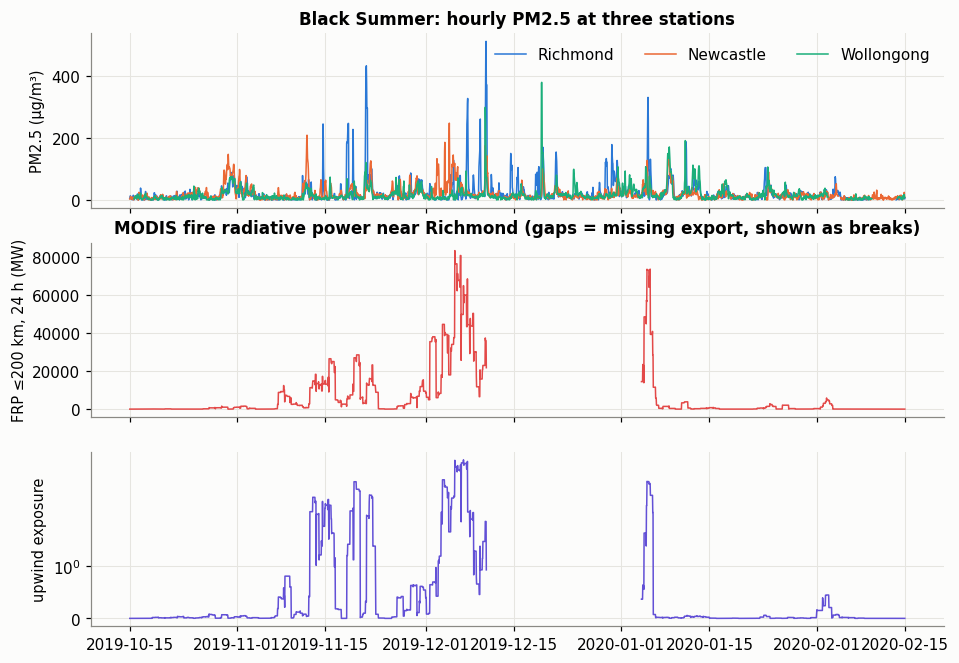

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
w = (FS["datetime"] >= "2019-10-15") & (FS["datetime"] <= "2020-02-15")
for s, c in zip(["Richmond", "Newcastle", "Wollongong"], [PAL["blue"], PAL["orange"], PAL["aqua"]]):
    d = FS[w & (FS.station == s)]
    axes[0].plot(d["datetime"], d["PM25_f"], color=c, lw=1, label=s)
axes[0].set_ylabel("PM2.5 (µg/m³)"); axes[0].legend(ncol=3); axes[0].set_title("Black Summer: hourly PM2.5 at three stations")
d = FS[w & (FS.station == "Richmond")]
axes[1].plot(d["datetime"], d["frp_200km_24h"], color=PAL["red"], lw=1); axes[1].set_ylabel("FRP ≤200 km, 24 h (MW)")
axes[1].set_title("MODIS fire radiative power near Richmond (gaps = missing export, shown as breaks)")
axes[2].plot(d["datetime"], d["upwind_expo_24h"], color=PAL["violet"], lw=1); axes[2].set_ylabel("upwind exposure"); axes[2].set_yscale("symlog")
savefig("02_eda_black_summer")

## 6. Student 2 — modelling set-up


In [12]:
FSi = FS.reset_index(drop=True)
tt = FSi["datetime"]
WINDOWS = {"ALL_TEST": (tt >= TEST_START), "BLACK_SUMMER": (tt >= BS_START) & (tt <= BS_END), "POST_EVENT": (tt >= POST_START)}

def masks(h):
    valid = FSi["pm25_now"].notna() & FSi[f"y_{h}h"].notna()
    tgt = tt + pd.Timedelta(hours=h)
    return {"train": valid & (tgt < VAL_START), "val": valid & (tt >= VAL_START) & (tgt < TEST_START), "test": valid & (tt >= TEST_START)}
MASK = {h: masks(h) for h in HORIZONS}
print(pd.DataFrame({h: {k: int(v.sum()) for k, v in MASK[h].items()} for h in HORIZONS}))
print("\nTrain-period PM2.5 max by station (what the models have 'seen'):")
print(FSi[FSi.datetime < VAL_START].groupby("station")["PM25"].max().round(0).to_dict())
print("Black Summer PM2.5 max by station:")
print(FSi[WINDOWS["BLACK_SUMMER"]].groupby("station")["PM25"].max().round(0).to_dict())
print(f"Black-Summer test hours with fire data missing (export gap): {FSi.loc[WINDOWS['BLACK_SUMMER'], 'fire_missing'].mean()*100:.1f}%")

           6       12      24      48
train  145647  145241  144761  144200
val     34961   34803   34605   34269
test   311522  310523  309016  307459

Train-period PM2.5 max by station (what the models have 'seen'):
{'Earlwood': 164.0, 'Liverpool': 205.0, 'Newcastle': 212.0, 'Richmond': 335.0, 'Wollongong': 150.0, 'Wyong': 83.0}
Black Summer PM2.5 max by station:
{'Earlwood': 365.0, 'Liverpool': 437.0, 'Newcastle': 248.0, 'Richmond': 513.0, 'Wollongong': 380.0, 'Wyong': 359.0}
Black-Summer test hours with fire data missing (export gap): 20.3%


In [13]:
def exceed_scores(y, p, thr):
    ob, fc = y >= thr, p >= thr
    hit, miss, fa = (ob & fc).sum(), (ob & ~fc).sum(), (~ob & fc).sum()
    pod = hit / (hit + miss) if hit + miss else np.nan
    far = fa / (hit + fa) if hit + fa else np.nan
    csi = hit / (hit + miss + fa) if hit + miss + fa else np.nan
    return pod, far, csi

def evaluate(y, p, p_base):
    y, p, p_base = map(np.asarray, (y, p, p_base)); ok = ~np.isnan(y) & ~np.isnan(p)
    y, p, pb = y[ok], np.clip(p[ok], 0, None), p_base[ok]
    if len(y) < 20: return {}
    err = p - y; mae = np.abs(err).mean(); mae_b = np.abs(pb - y).mean()
    r = {"n": len(y), "MAE": mae, "RMSE": np.sqrt((err ** 2).mean()), "R2": 1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum(),
         "bias": err.mean(), "MAE_skill_vs_persist": 1 - mae / mae_b}
    e = y >= 25
    r["n_elev25"] = int(e.sum()); r["MAE_elev25"] = np.abs(err[e]).mean() if e.sum() else np.nan
    r["bias_elev25"] = err[e].mean() if e.sum() else np.nan
    for thr in EXCEED:
        r[f"POD{thr}"], r[f"FAR{thr}"], r[f"CSI{thr}"] = exceed_scores(y, p, thr)
    return r

PRED = {}      # PRED[model][h] = array aligned with FSi rows (NaN where not predicted)
def store(model, h, idx, vals):
    PRED.setdefault(model, {}).setdefault(h, np.full(len(FSi), np.nan, dtype="float32"))[idx] = vals

def results_table(models=None, windows=("ALL_TEST", "BLACK_SUMMER", "POST_EVENT"), subset=None):
    rows = []
    for m in (models or list(PRED)):
        for h in HORIZONS:
            if h not in PRED[m]: continue
            for wn in windows:
                msk = (MASK[h]["test"] & WINDOWS[wn]).values
                if subset is not None: msk &= subset
                idx = np.where(msk)[0]
                r = evaluate(FSi[f"y_{h}h"].values[idx], PRED[m][h][idx], FSi["pm25_now"].values[idx])
                if r: rows.append({"model": m, "horizon_h": h, "window": wn, **r})
    return pd.DataFrame(rows)

## 7. Baselines
* **Persistence** – tomorrow looks like now (`ŷ(t+h) = PM2.5(t)`). Every model must beat this.
* **Climatology** – average PM2.5 for that station / month / hour-of-day in the training years (no information about current conditions).
* **Ridge regression** – a linear model on all features (the "simple learned model" step of the benchmark ladder).

In [14]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

for h in HORIZONS:
    te = np.where(MASK[h]["test"])[0]
    store("Persistence", h, te, FSi["pm25_now"].values[te])
    tr = MASK[h]["train"] | MASK[h]["val"]
    clim = FSi[tr].assign(th=lambda d: (d["hour"] + h) % 24, tm=lambda d: ((d["datetime"] + pd.Timedelta(hours=h)).dt.month)) \
                  .groupby(["station", "tm", "th"])[f"y_{h}h"].mean().rename("clim").reset_index()
    q = FSi.loc[te, ["station", "hour", "datetime"]].assign(th=lambda d: (d["hour"] + h) % 24, tm=lambda d: (d["datetime"] + pd.Timedelta(hours=h)).dt.month)
    store("Climatology", h, te, q.merge(clim, on=["station", "tm", "th"], how="left")["clim"].values)
    # ridge on the full feature set (residual target keeps it stable under extremes)
    trn = np.where(MASK[h]["train"] | MASK[h]["val"])[0]
    X = FSi[FULL].values; y = FSi[f"y_{h}h"].values - FSi["pm25_now"].values
    rg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0)).fit(X[trn], y[trn])
    store("Ridge", h, te, FSi["pm25_now"].values[te] + rg.predict(X[te]))
print(results_table(["Persistence", "Climatology", "Ridge"], windows=["ALL_TEST", "BLACK_SUMMER"])
      [["model", "horizon_h", "window", "MAE", "RMSE", "R2", "MAE_skill_vs_persist"]].round(2).to_string(index=False))

      model  horizon_h       window       MAE      RMSE    R2  MAE_skill_vs_persist
Persistence          6     ALL_TEST  5.460000 10.770000 -0.23                  0.00
Persistence          6 BLACK_SUMMER 14.390000 34.099998 -0.30                  0.00
Persistence         12     ALL_TEST  5.980000 11.880000 -0.49                  0.00
Persistence         12 BLACK_SUMMER 17.280001 38.180000 -0.63                  0.00
Persistence         24     ALL_TEST  5.410000 11.170000 -0.32                  0.00
Persistence         24 BLACK_SUMMER 17.690001 37.270000 -0.55                  0.00
Persistence         48     ALL_TEST  5.870000 11.970000 -0.52                  0.00
Persistence         48 BLACK_SUMMER 19.170000 39.380001 -0.73                  0.00
Climatology          6     ALL_TEST  5.000000  9.680000  0.01                  0.08
Climatology          6 BLACK_SUMMER 13.510000 31.750000 -0.13                  0.06
Climatology         12     ALL_TEST  5.000000  9.690000  0.01               

## 8. Gradient-boosted trees (LightGBM, XGBoost) with lag, fire, weather & neighbour features


In [15]:
import lightgbm as lgb
import xgboost as xgb

def to_target(kind, y, now):
    return {"level": y, "resid": y - now, "logratio": np.log1p(y) - np.log1p(now)}[kind]
def from_target(kind, z, now):
    return {"level": z, "resid": now + z, "logratio": np.expm1(np.log1p(now) + z)}[kind]

LGB_PARAMS = dict(n_estimators=2000 if not QUICK_MODE else 150, learning_rate=0.03, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1)

def fit_gbm(engine, kind, h, cols, train_idx, val_idx, test_idx, return_model=False):
    X = FSi[cols].values; now = FSi["pm25_now"].values; y = FSi[f"y_{h}h"].values
    z = to_target(kind, y, now)
    if engine == "lgb":
        m = lgb.LGBMRegressor(**LGB_PARAMS).fit(X[train_idx], z[train_idx], eval_set=[(X[val_idx], z[val_idx])],
                                                callbacks=[lgb.early_stopping(50, verbose=False)])
        best = max(int(m.best_iteration_ or LGB_PARAMS["n_estimators"]), 30)
        mf = lgb.LGBMRegressor(**{**LGB_PARAMS, "n_estimators": int(best * 1.1)}).fit(X[np.r_[train_idx, val_idx]], z[np.r_[train_idx, val_idx]])
        pv = from_target(kind, m.predict(X[val_idx]), now[val_idx])
    else:
        P = dict(n_estimators=2000 if not QUICK_MODE else 150, learning_rate=0.03, max_depth=6, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                 tree_method="hist", random_state=SEED, n_jobs=-1)
        m = xgb.XGBRegressor(**P, early_stopping_rounds=50).fit(X[train_idx], z[train_idx], eval_set=[(X[val_idx], z[val_idx])], verbose=False)
        best = max(int(m.best_iteration) + 1, 30)
        mf = xgb.XGBRegressor(**{**P, "n_estimators": int(best * 1.1)}).fit(X[np.r_[train_idx, val_idx]], z[np.r_[train_idx, val_idx]])
        pv = from_target(kind, m.predict(X[val_idx]), now[val_idx])
    pt = from_target(kind, mf.predict(X[test_idx]), now[test_idx])
    val_mae = np.abs(np.clip(pv, 0, None) - y[val_idx]).mean()
    return (pt, val_mae, best, mf) if return_model else (pt, val_mae, best)

GBM_VARIANTS = {"LightGBM": ("lgb", "level"), "LightGBM-resid": ("lgb", "resid"), "LightGBM-logratio": ("lgb", "logratio"), "XGBoost": ("xgb", "resid")}
if FAST_GBM: GBM_VARIANTS.pop("XGBoost")
val_scores, best_iters, GBM_MODELS = {}, {}, {}
t0 = time.time()
for name, (eng, kind) in GBM_VARIANTS.items():
    for h in HORIZONS:
        tr, va, te = [np.where(MASK[h][k])[0] for k in ("train", "val", "test")]
        pt, vmae, best, mdl = fit_gbm(eng, kind, h, FULL, tr, va, te, return_model=True)
        store(name, h, te, pt); val_scores[(name, h)] = vmae; best_iters[(name, h)] = best; GBM_MODELS[(name, h)] = mdl
    print(f"{name:18s} done ({time.time()-t0:.0f}s)  mean val MAE = {np.mean([val_scores[(name,h)] for h in HORIZONS]):.3f}")
VAL_TABLE = pd.Series({k: v for k, v in val_scores.items()}).unstack()
BEST_GBM = min(GBM_VARIANTS, key=lambda n: VAL_TABLE.loc[n].mean())
print("\nValidation MAE (Jan–Sep 2019) per variant/horizon:"); print(VAL_TABLE.round(3))
print("\nBEST_GBM chosen on validation:", BEST_GBM)
VAL_TABLE.to_csv(OUT_DIR / "gbm_validation_mae.csv")

LightGBM           done (98s)  mean val MAE = 4.477
LightGBM-resid     done (211s)  mean val MAE = 4.488
LightGBM-logratio  done (456s)  mean val MAE = 4.482
XGBoost            done (647s)  mean val MAE = 4.488

Validation MAE (Jan–Sep 2019) per variant/horizon:
                      6      12     24     48
LightGBM           4.164  4.369  4.504  4.871
LightGBM-logratio  4.156  4.387  4.559  4.825
LightGBM-resid     4.158  4.399  4.537  4.859
XGBoost            4.172  4.395  4.528  4.857

BEST_GBM chosen on validation: LightGBM


## 9. Deep learning: GRU, LSTM and Temporal Convolutional Network (TCN)



In [16]:
try:
    if SKIP_DL: raise ImportError("SKIP_DL=1")
    import torch, torch.nn as nn
    HAS_TORCH = True
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    torch.manual_seed(SEED)
    print("torch", torch.__version__, "| device:", DEVICE)
except Exception as e:
    HAS_TORCH = False; print("PyTorch not available -> deep-learning section skipped:", e)

SEQ_LEN = 48
SEQ_COLS = ["pm25_now", "log_pm25", "TEMP", "HUMIDITY", "Wind_speed", "wind_u", "wind_v", "Rainfall", "rainfall_missing",
            "frp_200km_24h", "fires_100km_24h", "nearest_fire_km_24h", "fire_expo_24h", "upwind_expo_24h", "upwind_frp_200km_24h",
            "nbr_upwind_lag1", "sin_hour", "cos_hour", "sin_month", "cos_month"]
LOG_COLS = {"frp_200km_24h", "fires_100km_24h", "nearest_fire_km_24h", "fire_expo_24h", "upwind_expo_24h", "upwind_frp_200km_24h"}

if HAS_TORCH:
    Xs = FSi[SEQ_COLS].copy()
    for c in LOG_COLS: Xs[c] = np.log1p(Xs[c])
    trn_rows = (FSi["datetime"] < VAL_START).values
    mu, sd = Xs[trn_rows].mean(), Xs[trn_rows].std().replace(0, 1)
    Z = ((Xs - mu) / sd).clip(-8, 12)
    pm_missing = Z["pm25_now"].isna().astype("float32").values; fire_missing_ = FSi["fire_missing"].values.astype("float32")
    Z = Z.fillna(0.0).astype("float32").values
    Z = np.concatenate([Z, pm_missing[:, None], fire_missing_[:, None]], axis=1)          # + 2 mask channels
    NF = Z.shape[1]
    A = Z.reshape(S_N, T, NF)                                                             # [station, time, feature]
    NOW = FSi["pm25_now"].values.reshape(S_N, T)
    Y = np.stack([FSi[f"y_{h}h"].values.reshape(S_N, T) for h in HORIZONS], axis=-1)     # [S, T, 4]
    R = Y - NOW[..., None]
    sig = np.array([np.nanstd(np.where(MASK[h]["train"].values.reshape(S_N, T), R[..., k], np.nan)) for k, h in enumerate(HORIZONS)])
    print("residual scale per horizon (training years):", sig.round(2), "| channels:", NF)
    MK = {sp: np.stack([MASK[h][sp].values.reshape(S_N, T) for h in HORIZONS], axis=-1) for sp in ("train", "val", "test")}
    OFFS = np.arange(-SEQ_LEN + 1, 1)

    def origins(sp):
        ok = MK[sp].any(-1) & (np.arange(T)[None, :] >= SEQ_LEN) & ~np.isnan(NOW)
        s_i, t_i = np.where(ok); return s_i, t_i
    def batch(s_i, t_i):
        return torch.from_numpy(A[s_i[:, None], t_i[:, None] + OFFS[None, :]])
    def targets(s_i, t_i):
        r = R[s_i, t_i] / sig; m = MK["train"][s_i, t_i]
        return torch.from_numpy(np.nan_to_num(r).astype("float32")), torch.from_numpy(m.astype("float32"))

    class RNNNet(nn.Module):
        def __init__(self, kind, nf, hid=96, layers=2, drop=0.2, nout=4):
            super().__init__()
            Cell = nn.GRU if kind == "GRU" else nn.LSTM
            self.rnn = Cell(nf, hid, layers, batch_first=True, dropout=drop)
            self.head = nn.Sequential(nn.Linear(hid, 64), nn.ReLU(), nn.Dropout(drop), nn.Linear(64, nout))
        def forward(self, x):
            o, _ = self.rnn(x); return self.head(o[:, -1])

    class Chomp(nn.Module):
        def __init__(self, n): super().__init__(); self.n = n
        def forward(self, x): return x[:, :, :-self.n] if self.n else x
    class TCNBlock(nn.Module):
        def __init__(self, cin, cout, k, dil, drop):
            super().__init__(); pad = (k - 1) * dil
            self.net = nn.Sequential(nn.Conv1d(cin, cout, k, padding=pad, dilation=dil), Chomp(pad), nn.ReLU(), nn.Dropout(drop),
                                     nn.Conv1d(cout, cout, k, padding=pad, dilation=dil), Chomp(pad), nn.ReLU(), nn.Dropout(drop))
            self.down = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity()
        def forward(self, x): return torch.relu(self.net(x) + self.down(x))
    class TCNNet(nn.Module):
        def __init__(self, nf, ch=64, k=3, dils=(1, 2, 4, 8), drop=0.2, nout=4):
            super().__init__()
            blocks, cin = [], nf
            for d in dils: blocks.append(TCNBlock(cin, ch, k, d, drop)); cin = ch
            self.tcn = nn.Sequential(*blocks); self.head = nn.Sequential(nn.Linear(ch, 64), nn.ReLU(), nn.Linear(64, nout))
        def forward(self, x): return self.head(self.tcn(x.transpose(1, 2))[:, :, -1])   # causal: last step sees only the past

    def masked_huber(pred, tgt, m, delta=2.0):
        e = torch.nn.functional.huber_loss(pred, tgt, reduction="none", delta=delta)
        return (e * m).sum() / m.sum().clamp(min=1)

    def predict_seq(model, s_i, t_i, bs=2048):
        model.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(s_i), bs):
                out.append(model(batch(s_i[i:i + bs], t_i[i:i + bs]).to(DEVICE)).cpu().numpy())
        return np.concatenate(out) * sig + NOW[s_i, t_i][:, None]

    def train_seq(kind, epochs=14, bs=512, lr=2e-3, patience=4):
        torch.manual_seed(SEED); np.random.seed(SEED)
        model = (RNNNet(kind, NF) if kind in ("GRU", "LSTM") else TCNNet(NF)).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=1)
        tr_s, tr_t = origins("train"); va_s, va_t = origins("val")
        tr_s, tr_t = tr_s[::DL_STRIDE], tr_t[::DL_STRIDE]; va_s, va_t = va_s[::max(1, DL_STRIDE)], va_t[::max(1, DL_STRIDE)]
        best, best_state, bad = 1e9, None, 0
        for ep in range(epochs):
            model.train(); perm = np.random.permutation(len(tr_s)); tl = 0; nb = 0; t1 = time.time()
            for i in range(0, len(perm), bs):
                b = perm[i:i + bs]; xb = batch(tr_s[b], tr_t[b]).to(DEVICE); yb, mb = targets(tr_s[b], tr_t[b])
                opt.zero_grad(); loss = masked_huber(model(xb), yb.to(DEVICE), mb.to(DEVICE)); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tl += loss.item(); nb += 1
            pv = predict_seq(model, va_s, va_t); mk = MK["val"][va_s, va_t]
            vmae = np.nanmean(np.where(mk, np.abs(np.clip(pv, 0, None) - Y[va_s, va_t]), np.nan))
            sched.step(vmae)
            print(f"  {kind} epoch {ep+1:2d}  train loss {tl/nb:.4f}  val MAE {vmae:.3f}  ({time.time()-t1:.0f}s)")
            if vmae < best - 1e-4: best, bad = vmae, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= patience: break
        model.load_state_dict(best_state); return model, best

    DL_VAL = {}
    for kind in (["GRU", "LSTM", "TCN"] if not QUICK_MODE else ["GRU"]):
        t0 = time.time(); print(f"Training {kind} ...")
        try:
            model, vmae = train_seq(kind, epochs=DL_EPOCHS if not QUICK_MODE else 2)
            te_s, te_t = origins("test"); P = predict_seq(model, te_s, te_t)
            for k, h in enumerate(HORIZONS):
                ok = MASK[h]["test"].values.reshape(S_N, T)[te_s, te_t]
                store(kind, h, (te_s * T + te_t)[ok], P[ok, k])
            DL_VAL[kind] = vmae; print(f"{kind}: best val MAE {vmae:.3f}  ({time.time()-t0:.0f}s)")
        except Exception as e:      # a failure in one network must not lose the other results
            print(f"!! {kind} failed and is skipped: {e!r}")

torch 2.11.0+cpu | device: cpu
residual scale per horizon (training years): [8.48 9.44 9.2  9.81] | channels: 22
Training GRU ...
  GRU epoch  1  train loss 0.2286  val MAE 4.554  (151s)
  GRU epoch  2  train loss 0.2084  val MAE 4.509  (148s)
  GRU epoch  3  train loss 0.2007  val MAE 4.439  (147s)
  GRU epoch  4  train loss 0.1924  val MAE 4.667  (148s)
  GRU epoch  5  train loss 0.1853  val MAE 4.561  (150s)
  GRU epoch  6  train loss 0.1736  val MAE 4.611  (147s)
  GRU epoch  7  train loss 0.1684  val MAE 4.623  (146s)
GRU: best val MAE 4.439  (1147s)
Training LSTM ...
  LSTM epoch  1  train loss 0.2296  val MAE 4.549  (226s)
  LSTM epoch  2  train loss 0.2069  val MAE 4.543  (226s)
  LSTM epoch  3  train loss 0.1995  val MAE 4.478  (225s)
  LSTM epoch  4  train loss 0.1930  val MAE 4.639  (224s)
  LSTM epoch  5  train loss 0.1848  val MAE 4.542  (224s)
  LSTM epoch  6  train loss 0.1731  val MAE 4.575  (225s)
  LSTM epoch  7  train loss 0.1680  val MAE 4.609  (227s)
LSTM: best val

## 10. Results: forecasting accuracy at different horizons


===== BLACK_SUMMER: MAE (µg/m³) by model and horizon =====
horizon_h             6          12         24     48
model                                                
Persistence        14.39  17.280001  17.690001  19.17
Climatology        13.51  13.470000  13.390000  13.25
Ridge              15.89  16.940001  14.820000  14.28
LightGBM           15.05  16.290001  12.650000  13.22
LightGBM-resid     14.86  15.000000  13.260000  13.93
LightGBM-logratio  11.92  12.770000  13.260000  13.34
XGBoost            15.89  18.820000  14.010000  14.78
GRU                12.27  13.240000  14.010000  14.25
LSTM               12.05  13.380000  13.830000  13.94
TCN                12.13  13.320000  13.990000  14.23
----- BLACK_SUMMER: MAE skill vs persistence -----
horizon_h             6      12     24     48
model                                        
Persistence        0.000  0.000  0.000  0.000
Climatology        0.061  0.220  0.243  0.309
Ridge             -0.104  0.019  0.162  0.255
LightGBM   

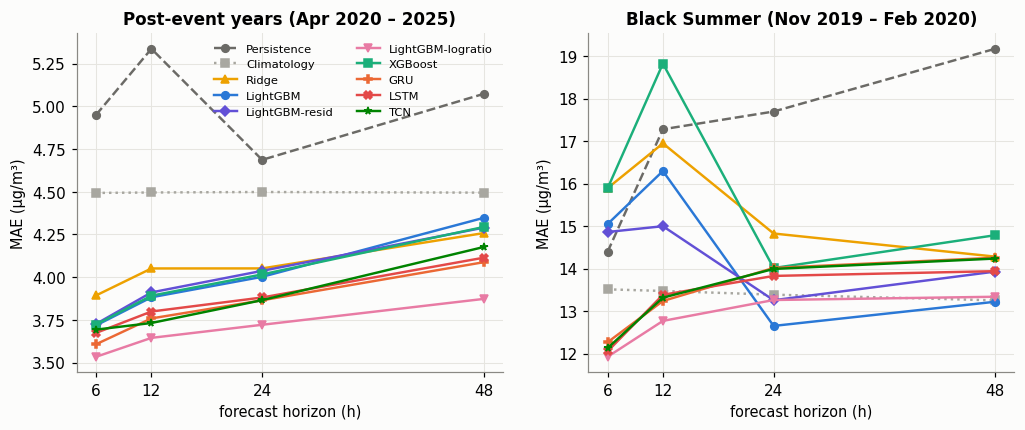

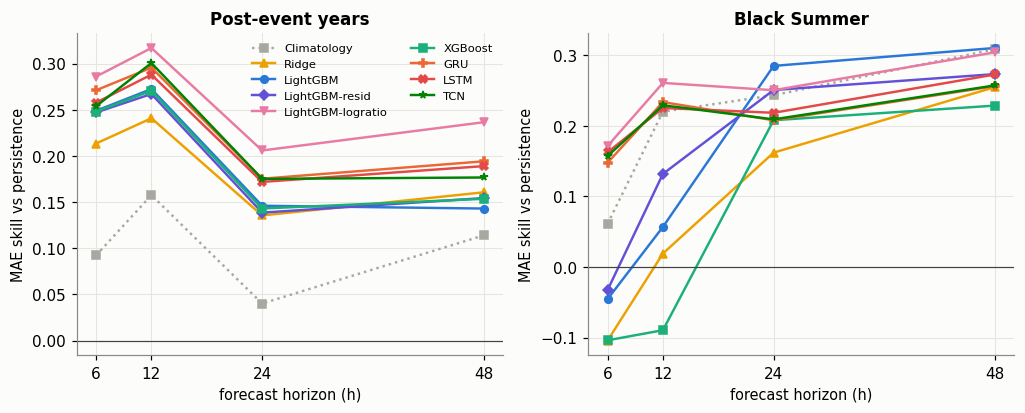

In [17]:
RES = results_table()
RES.to_csv(OUT_DIR / "results_all_models.csv", index=False)
MAIN = ["Persistence", "Climatology", "Ridge", "LightGBM", "LightGBM-resid", "LightGBM-logratio", "XGBoost", "GRU", "LSTM", "TCN"]
MAIN = [m for m in MAIN if m in PRED]
for wn in ["BLACK_SUMMER", "POST_EVENT"]:
    print(f"\n===== {wn}: MAE (µg/m³) by model and horizon ====="); print(RES[RES.window == wn].pivot(index="model", columns="horizon_h", values="MAE").reindex(MAIN).round(2))
    print(f"----- {wn}: MAE skill vs persistence -----");            print(RES[RES.window == wn].pivot(index="model", columns="horizon_h", values="MAE_skill_vs_persist").reindex(MAIN).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, wn, ttl in zip(axes, ["POST_EVENT", "BLACK_SUMMER"], ["Post-event years (Apr 2020 – 2025)", "Black Summer (Nov 2019 – Feb 2020)"]):
    for m in MAIN:
        d = RES[(RES.model == m) & (RES.window == wn)].sort_values("horizon_h")
        c, mk, ls = MODEL_STYLE[m]; ax.plot(d["horizon_h"], d["MAE"], color=c, marker=mk, ls=ls, ms=5, label=m)
    ax.set_xticks(HORIZONS); ax.set_xlabel("forecast horizon (h)"); ax.set_ylabel("MAE (µg/m³)"); ax.set_title(ttl)
axes[0].legend(fontsize=7.5, ncol=2)
savefig("03_mae_vs_horizon")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, wn, ttl in zip(axes, ["POST_EVENT", "BLACK_SUMMER"], ["Post-event years", "Black Summer"]):
    for m in [x for x in MAIN if x not in ("Persistence",)]:
        d = RES[(RES.model == m) & (RES.window == wn)].sort_values("horizon_h")
        c, mk, ls = MODEL_STYLE[m]; ax.plot(d["horizon_h"], d["MAE_skill_vs_persist"], color=c, marker=mk, ls=ls, ms=5, label=m)
    ax.axhline(0, color="#444", lw=0.8); ax.set_xticks(HORIZONS); ax.set_xlabel("forecast horizon (h)"); ax.set_ylabel("MAE skill vs persistence"); ax.set_title(ttl)
axes[0].legend(fontsize=7.5, ncol=2)
savefig("04_skill_vs_persistence")

## 11. Performance during the major wildfire episode (Black Summer)


      model  horizon_h     n       MAE  MAE_elev25  bias_elev25  POD25  FAR25  CSI25  POD50  FAR50  CSI50
        GRU          6 16218 12.270000   44.330002   -38.410000   0.18   0.48   0.16   0.10   0.50   0.09
       LSTM          6 16218 12.050000   43.060001   -36.490002   0.25   0.45   0.21   0.11   0.48   0.10
   LightGBM          6 16218 15.050000   35.900002   -25.309999   0.59   0.61   0.30   0.35   0.76   0.17
Persistence          6 16218 14.390000   41.779999   -19.510000   0.50   0.50   0.33   0.36   0.64   0.22
        TCN          6 16218 12.130000   43.770000   -37.410000   0.24   0.43   0.20   0.12   0.47   0.11
        GRU         12 16138 13.240000   47.770000   -43.259998   0.11   0.58   0.10   0.05   0.69   0.05
       LSTM         12 16138 13.380000   46.680000   -41.380001   0.19   0.56   0.15   0.06   0.70   0.05
   LightGBM         12 16138 16.290001   39.650002   -30.760000   0.45   0.68   0.23   0.27   0.80   0.13
Persistence         12 16138 17.280001   46.66

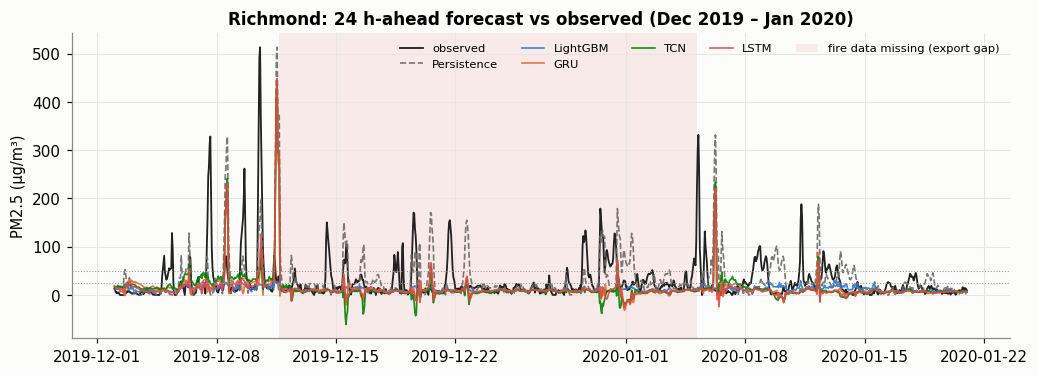

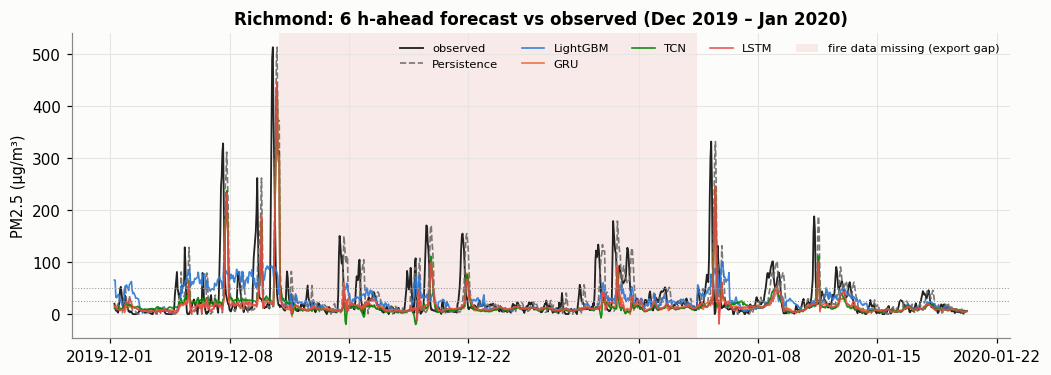

In [18]:
SHOW = ["Persistence", BEST_GBM] + [m for m in ["GRU", "TCN", "LSTM"] if m in PRED]
EV = RES[(RES.window == "BLACK_SUMMER") & (RES.model.isin(SHOW))][["model", "horizon_h", "n", "MAE", "MAE_elev25", "bias_elev25", "POD25", "FAR25", "CSI25", "POD50", "FAR50", "CSI50"]]
print(EV.round(2).sort_values(["horizon_h", "model"]).to_string(index=False)); EV.to_csv(OUT_DIR / "black_summer_event_scores.csv", index=False)

for h_show, stn in [(24, "Richmond"), (6, "Richmond")]:
    m = (FSi["station"] == stn) & (FSi["datetime"] >= "2019-12-01") & (FSi["datetime"] <= "2020-01-20")
    idx = np.where(m & MASK[h_show]["test"])[0]
    tgt_time = FSi["datetime"].values[idx] + np.timedelta64(h_show, "h")
    fig, ax = plt.subplots(figsize=(11, 3.6))
    ax.plot(tgt_time, FSi[f"y_{h_show}h"].values[idx], color="#222", lw=1.2, label="observed")
    for mname in SHOW:
        c, mk, ls = MODEL_STYLE[mname]; ax.plot(tgt_time, PRED[mname][h_show][idx], color=c, lw=1.1, ls=ls, label=mname, alpha=0.9)
    ax.axhline(25, color="#999", lw=0.7, ls=":"); ax.axhline(50, color="#999", lw=0.7, ls=":")
    gap_t = FSi["datetime"].values[idx][FSi["fire_missing"].values[idx] == 1] + np.timedelta64(h_show, "h")
    if len(gap_t): ax.axvspan(gap_t.min(), gap_t.max(), color="#f3c9c9", alpha=0.35, lw=0, label="fire data missing (export gap)")
    ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_title(f"{stn}: {h_show} h-ahead forecast vs observed (Dec 2019 – Jan 2020)"); ax.legend(ncol=5, fontsize=7.5)
    savefig(f"05_blacksummer_timeseries_{stn}_{h_show}h")

## 12. Geographic variation: per-station skill and leave-one-station-out (spatial validation)
* **Per-station table** – does accuracy differ by location?
* **Leave-one-station-out (LOSO)** – train on 5 stations, test on the 6th *which the model never saw*, over the same test period. Compared with the model that *did* train on that station, the gap shows how well forecasts transfer to a new location (the project brief's "spatial validation").

window     BLACK_SUMMER        POST_EVENT      
horizon_h            6      24         6     24
station                                        
Earlwood      13.310000  10.77       3.30  3.69
Liverpool     15.540000  13.82       3.99  4.32
Newcastle     13.950000  11.44       3.63  3.83
Richmond      19.049999  16.33       3.97  4.29
Wollongong    14.130000  12.01       3.84  4.18
Wyong         14.580000  11.91       3.60  3.72

Skill vs persistence (best GBM):
window     BLACK_SUMMER        POST_EVENT       
horizon_h            6      24         6      24
station                                         
Earlwood         -0.082  0.265      0.238  0.134
Liverpool         0.049  0.250      0.271  0.176
Newcastle        -0.140  0.295      0.291  0.155
Richmond          0.075  0.316      0.243  0.144
Wollongong       -0.112  0.288      0.235  0.165
Wyong            -0.154  0.285      0.207  0.090

Leave-one-station-out (best GBM): MAE when the station WAS vs was NOT in training
   station

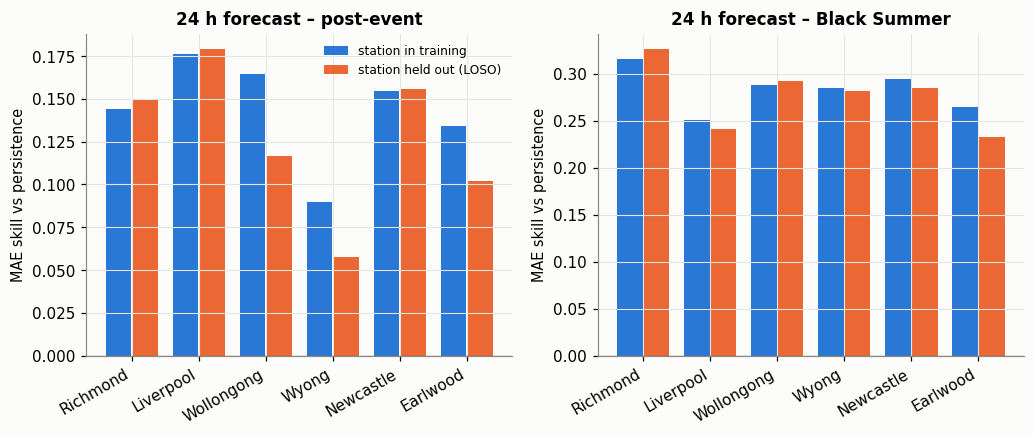

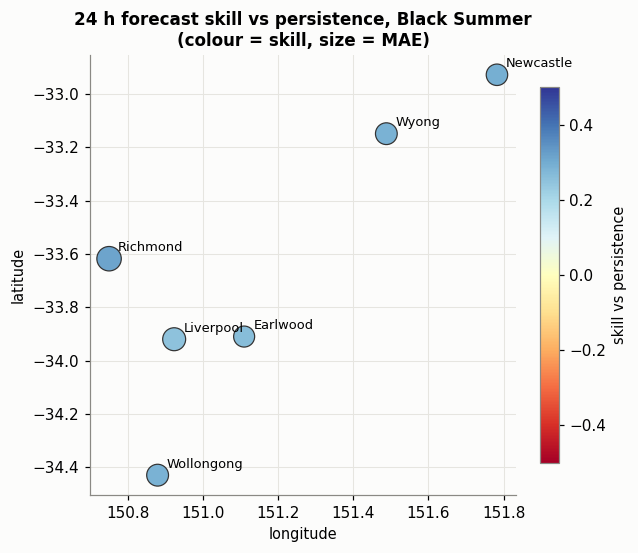

In [19]:
rows = []
for stn in STATIONS:
    sub = (FSi["station"] == stn).values
    for m in ["Persistence", BEST_GBM] + [x for x in ["GRU", "TCN"] if x in PRED]:
        for h in (6, 24):
            for wn in ("BLACK_SUMMER", "POST_EVENT"):
                msk = (MASK[h]["test"] & WINDOWS[wn]).values & sub; idx = np.where(msk)[0]
                r = evaluate(FSi[f"y_{h}h"].values[idx], PRED[m][h][idx], FSi["pm25_now"].values[idx])
                if r: rows.append({"station": stn, "model": m, "horizon_h": h, "window": wn, **r})
BYST = pd.DataFrame(rows); BYST.to_csv(OUT_DIR / "per_station_results.csv", index=False)
print(BYST[(BYST.model == BEST_GBM)].pivot_table(index="station", columns=["window", "horizon_h"], values="MAE").round(2))
print("\nSkill vs persistence (best GBM):")
print(BYST[(BYST.model == BEST_GBM)].pivot_table(index="station", columns=["window", "horizon_h"], values="MAE_skill_vs_persist").round(3))

# LOSO with the best GBM variant
eng, kind = GBM_VARIANTS[BEST_GBM]
loso_rows = []
for stn in STATIONS:
    held = (FSi["station"] == stn).values
    for h in (6, 24):
        tr = np.where(MASK[h]["train"].values & ~held)[0]; va = np.where(MASK[h]["val"].values & ~held)[0]
        te = np.where(MASK[h]["test"].values & held)[0]
        pt, _, _ = fit_gbm(eng, kind, h, FULL, tr, va, te)
        for wn in ("BLACK_SUMMER", "POST_EVENT"):
            sel = WINDOWS[wn].values[te]; pooled = PRED[BEST_GBM][h][te][sel]
            args = (FSi[f"y_{h}h"].values[te][sel], None, FSi["pm25_now"].values[te][sel])
            r_un = evaluate(args[0], pt[sel], args[2]); r_seen = evaluate(args[0], pooled, args[2])
            if r_un and r_seen:
                loso_rows.append({"station": stn, "horizon_h": h, "window": wn, "MAE_seen_station": r_seen["MAE"], "MAE_unseen_station": r_un["MAE"],
                                  "skill_seen": r_seen["MAE_skill_vs_persist"], "skill_unseen": r_un["MAE_skill_vs_persist"]})
LOSO = pd.DataFrame(loso_rows); LOSO.to_csv(OUT_DIR / "loso_spatial_validation.csv", index=False)
print("\nLeave-one-station-out (best GBM): MAE when the station WAS vs was NOT in training"); print(LOSO.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, wn in zip(axes, ["POST_EVENT", "BLACK_SUMMER"]):
    d = LOSO[(LOSO.window == wn) & (LOSO.horizon_h == 24)].set_index("station").loc[STATIONS]
    x = np.arange(len(d)); ax.bar(x - 0.2, d["skill_seen"], 0.38, color=PAL["blue"], label="station in training")
    ax.bar(x + 0.2, d["skill_unseen"], 0.38, color=PAL["orange"], label="station held out (LOSO)")
    ax.axhline(0, color="#444", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(d.index, rotation=30, ha="right")
    ax.set_ylabel("MAE skill vs persistence"); ax.set_title(f"24 h forecast – {'Black Summer' if wn=='BLACK_SUMMER' else 'post-event'}")
axes[0].legend(fontsize=8); savefig("06_loso_spatial_validation")

# map of per-station skill (24 h, Black Summer) – bubble size = MAE
d = BYST[(BYST.model == BEST_GBM) & (BYST.horizon_h == 24) & (BYST.window == "BLACK_SUMMER")].set_index("station").loc[STATIONS]
fig, ax = plt.subplots(figsize=(5.5, 5.2))
sc = ax.scatter(st["longitude"], st["latitude"], s=60 + 12 * d["MAE"].values, c=d["MAE_skill_vs_persist"].values, cmap="RdYlBu", vmin=-0.5, vmax=0.5,
                edgecolor="#333", lw=0.8, zorder=3)
for s_, r in st.iterrows(): ax.annotate(s_, (r["longitude"], r["latitude"]), xytext=(6, 5), textcoords="offset points", fontsize=8.5)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title("24 h forecast skill vs persistence, Black Summer\n(colour = skill, size = MAE)")
plt.colorbar(sc, ax=ax, fraction=0.04, label="skill vs persistence"); savefig("07_station_map_skill")

## 13. Event-based validation: train *without* Black Summer, test on it


In [20]:
ev_rows = []
for h in HORIZONS:
    valid = MASK[h]["train"] | MASK[h]["val"] | MASK[h]["test"]
    tgt = tt + pd.Timedelta(hours=h)
    in_bs = (tt <= BS_END + pd.Timedelta(hours=h)) & (tgt >= BS_START - pd.Timedelta(hours=1)) & (tt >= BS_START - pd.Timedelta(hours=h))   # origin or target touches the event
    tr_all = np.where(valid.values & ~in_bs.values)[0]
    # hold out the last 10% of the non-event rows (chronologically) for early stopping
    cut = int(len(tr_all) * 0.9); tr, va = tr_all[:cut], tr_all[cut:]
    te = np.where((valid & WINDOWS["BLACK_SUMMER"]).values)[0]
    pt, _, _ = fit_gbm(eng, kind, h, FULL, tr, va, te)
    idx = te
    r = evaluate(FSi[f"y_{h}h"].values[idx], pt, FSi["pm25_now"].values[idx]); r_main = evaluate(FSi[f"y_{h}h"].values[idx], PRED[BEST_GBM][h][idx], FSi["pm25_now"].values[idx])
    r_p = evaluate(FSi[f"y_{h}h"].values[idx], FSi["pm25_now"].values[idx], FSi["pm25_now"].values[idx])
    ev_rows.append({"horizon_h": h, "MAE_persistence": r_p["MAE"], "MAE_temporal_split(train 2016-18)": r_main["MAE"], "MAE_event_held_out(train all other years)": r["MAE"],
                    "skill_temporal": r_main["MAE_skill_vs_persist"], "skill_event_held_out": r["MAE_skill_vs_persist"],
                    "MAE_elev25_temporal": r_main["MAE_elev25"], "MAE_elev25_event_held_out": r["MAE_elev25"]})
EVT = pd.DataFrame(ev_rows); EVT.to_csv(OUT_DIR / "event_held_out_validation.csv", index=False)
print(EVT.round(3).to_string(index=False))

 horizon_h  MAE_persistence  MAE_temporal_split(train 2016-18)  MAE_event_held_out(train all other years)  skill_temporal  skill_event_held_out  MAE_elev25_temporal  MAE_elev25_event_held_out
         6           14.392                          15.046000                                     12.766          -0.045                 0.113            35.902000                     35.585
        12           17.277                          16.294001                                     16.338           0.057                 0.054            39.653000                     38.131
        24           17.694                          12.651000                                     17.869           0.285                -0.010            48.581001                     39.275
        48           19.170                          13.219000                                     15.441           0.310                 0.194            50.273998                     42.127


## 14. Does fire activity actually help? Feature-group ablation + feature importance


window                        BLACK_SUMMER        POST_EVENT      
horizon_h                               6      24         6     24
features                                                          
PM+TIME                              12.09  12.76       3.83  4.02
+MET                                 11.92  12.63       3.74  3.98
+FIRE                                14.94  12.65       3.78  4.01
+NEIGHBOURS (full)                   15.05  12.65       3.72  4.00
NO PM history (MET+FIRE+TIME)        14.00  13.16       4.18  4.33


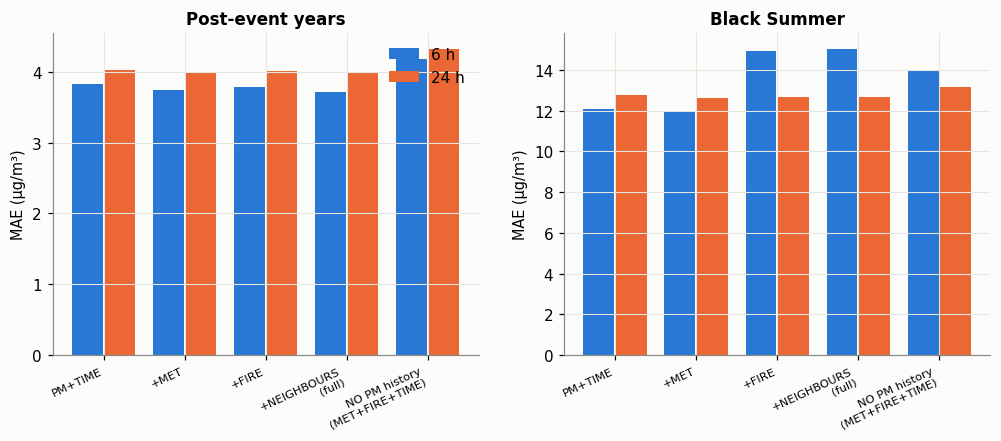

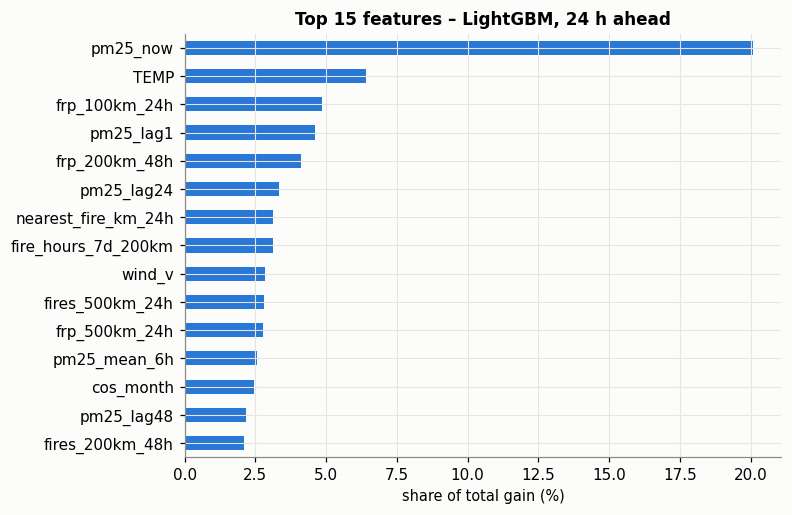

pm25_now               20.1
TEMP                    6.4
frp_100km_24h           4.9
pm25_lag1               4.6
frp_200km_48h           4.1
pm25_lag24              3.3
nearest_fire_km_24h     3.1
fire_hours_7d_200km     3.1
wind_v                  2.8
fires_500km_24h         2.8
frp_500km_24h           2.8
pm25_mean_6h            2.6
dtype: float64

Gain share by feature group (24 h): {'PM history': 40.1, 'Time': 5.3, 'Weather': 13.8, 'Fire': 36.4, 'Neighbour stations': 4.4}


In [21]:
ABL = {"PM+TIME": GROUPS["PM+TIME"], "+MET": GROUPS["+MET"], "+FIRE": GROUPS["+FIRE"], "+NEIGHBOURS (full)": FULL,
       "NO PM history (MET+FIRE+TIME)": TIME_COLS + MET_COLS + FIRE_ALL}
ab_rows = []
for gname, cols in ABL.items():
    for h in (6, 24):
        tr, va, te = [np.where(MASK[h][k])[0] for k in ("train", "val", "test")]
        pt, _, _ = fit_gbm(eng, kind, h, cols, tr, va, te)
        for wn in ("BLACK_SUMMER", "POST_EVENT"):
            sel = WINDOWS[wn].values[te]
            r = evaluate(FSi[f"y_{h}h"].values[te][sel], pt[sel], FSi["pm25_now"].values[te][sel])
            ab_rows.append({"features": gname, "horizon_h": h, "window": wn, "MAE": r["MAE"], "skill_vs_persist": r["MAE_skill_vs_persist"], "MAE_elev25": r["MAE_elev25"]})
ABLT = pd.DataFrame(ab_rows); ABLT.to_csv(OUT_DIR / "ablation_feature_groups.csv", index=False)
print(ABLT.pivot_table(index="features", columns=["window", "horizon_h"], values="MAE").reindex(list(ABL)).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, wn, ttl in zip(axes, ["POST_EVENT", "BLACK_SUMMER"], ["Post-event years", "Black Summer"]):
    d = ABLT[(ABLT.window == wn)].pivot(index="features", columns="horizon_h", values="MAE").reindex(list(ABL))
    x = np.arange(len(d)); ax.bar(x - 0.2, d[6], 0.38, color=PAL["blue"], label="6 h"); ax.bar(x + 0.2, d[24], 0.38, color=PAL["orange"], label="24 h")
    ax.set_xticks(x); ax.set_xticklabels([s.replace(" (", "\n(") for s in d.index], rotation=25, ha="right", fontsize=7.5); ax.set_ylabel("MAE (µg/m³)"); ax.set_title(ttl)
axes[0].legend(); savefig("08_ablation_feature_groups")

# feature importance of the full model (gain), 24 h horizon
mdl = GBM_MODELS[(BEST_GBM, 24)] if (BEST_GBM, 24) in GBM_MODELS else None
if mdl is not None and hasattr(mdl, "booster_"):
    imp = pd.Series(mdl.booster_.feature_importance("gain"), index=FULL).sort_values(ascending=False)
else:
    imp = pd.Series(mdl.feature_importances_, index=FULL).sort_values(ascending=False)
imp = imp / imp.sum() * 100; imp.to_csv(OUT_DIR / "feature_importance_24h.csv")
fig, ax = plt.subplots(figsize=(7, 5)); imp.head(15)[::-1].plot.barh(ax=ax, color=PAL["blue"]); ax.set_xlabel("share of total gain (%)"); ax.set_title(f"Top 15 features – {BEST_GBM}, 24 h ahead")
savefig("09_feature_importance"); print(imp.head(12).round(1))
grp = {"PM history": PM_COLS, "Time": TIME_COLS, "Weather": MET_COLS, "Fire": FIRE_ALL, "Neighbour stations": NBR_COLS}
print("\nGain share by feature group (24 h):", {k: round(float(imp[[c for c in v if c in imp.index]].sum()), 1) for k, v in grp.items()})

## 15. How does smoke propagate between locations? (cross-correlation analysis)


Lag (hours) at which column station best follows row station:
            Richmond  Liverpool  Wollongong  Wyong  Newcastle  Earlwood
Richmond         NaN       -1.0        -1.0    1.0       -1.0      -2.0
Liverpool        1.0        NaN        -1.0    1.0        1.0       0.0
Wollongong       1.0        1.0         NaN    2.0        0.0       0.0
Wyong           -1.0       -1.0        -2.0    NaN        0.0      -1.0
Newcastle        1.0       -1.0         0.0    0.0        NaN      -1.0
Earlwood         2.0        0.0         0.0    1.0        1.0       NaN

Peak correlation:
            Richmond  Liverpool  Wollongong  Wyong  Newcastle  Earlwood
Richmond         NaN       0.52        0.43   0.35       0.37      0.43
Liverpool       0.52        NaN        0.50   0.48       0.45      0.67
Wollongong      0.43       0.50         NaN   0.39       0.38      0.50
Wyong           0.35       0.48        0.39    NaN       0.43      0.55
Newcastle       0.37       0.45        0.38   0.43     

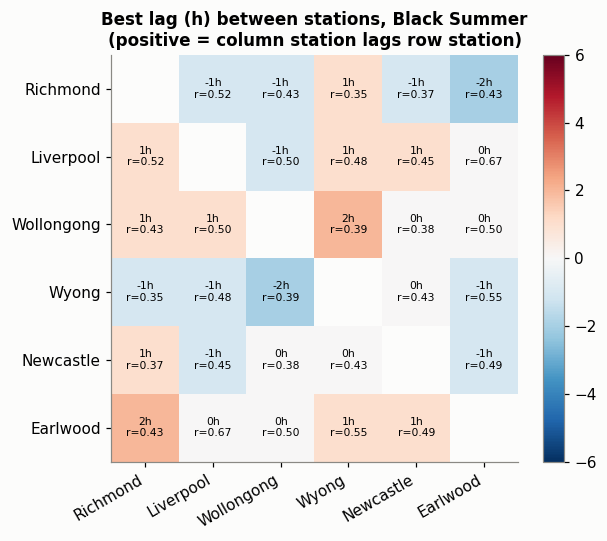

In [22]:
bs = (FSi["datetime"] >= "2019-11-01") & (FSi["datetime"] <= "2020-02-29")
wide = FSi[bs].pivot(index="datetime", columns="station", values="PM25_f")[STATIONS].apply(np.log1p)
wide = wide - wide.rolling(24 * 7, min_periods=24, center=True).mean()                         # remove slow trend -> focus on the plume signal
lags = range(-12, 13); best = pd.DataFrame(index=STATIONS, columns=STATIONS, dtype=float); bestc = best.copy()
for a in STATIONS:
    for b in STATIONS:
        if a == b: continue
        cs = [wide[a].corr(wide[b].shift(-L)) for L in lags]           # corr(a(t), b(t+L))
        k = int(np.nanargmax(cs)); best.loc[a, b] = list(lags)[k]; bestc.loc[a, b] = cs[k]
print("Lag (hours) at which column station best follows row station:"); print(best.round(0))
print("\nPeak correlation:"); print(bestc.round(2))
best.to_csv(OUT_DIR / "propagation_best_lag_hours.csv"); bestc.to_csv(OUT_DIR / "propagation_peak_corr.csv")
fig, ax = plt.subplots(figsize=(6, 4.8)); im = ax.imshow(best.astype(float).values, cmap="RdBu_r", vmin=-6, vmax=6)
ax.set_xticks(range(S_N)); ax.set_xticklabels(STATIONS, rotation=30, ha="right"); ax.set_yticks(range(S_N)); ax.set_yticklabels(STATIONS); ax.grid(False)
for i in range(S_N):
    for j in range(S_N):
        if i != j: ax.text(j, i, f"{int(best.values[i, j])}h\nr={bestc.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Best lag (h) between stations, Black Summer\n(positive = column station lags row station)"); plt.colorbar(im, ax=ax, fraction=0.04); savefig("10_propagation_lag")

## 16. Final comparison table + hand-off files for Student 1 and Student 3

In [23]:
summary = RES[RES.window.isin(["BLACK_SUMMER", "POST_EVENT"])].pivot_table(index=["window", "model"], columns="horizon_h", values=["MAE", "MAE_skill_vs_persist"]).round(3)
summary.to_csv(OUT_DIR / "summary_mae_and_skill.csv"); print(summary.loc[:, "MAE"].reindex(MAIN, level=1).to_string() if False else summary.to_string())

# Student 3 hand-off: out-of-sample forecasts + observations for every test hour (use to derive exceedance probabilities / warning classes)
keep = ["Persistence", BEST_GBM] + [m for m in ["GRU", "LSTM", "TCN"] if m in PRED]
parts_ = []
for h in HORIZONS:
    idx = np.where(MASK[h]["test"].values)[0]
    d = FSi.loc[idx, ["station", "datetime", "pm25_now"]].copy(); d["horizon_h"] = h; d["target_time"] = d["datetime"] + pd.Timedelta(hours=h)
    d["y_true"] = FSi[f"y_{h}h"].values[idx]
    for m in keep: d[f"pred_{m}"] = np.clip(PRED[m][h][idx], 0, None)
    parts_.append(d)
pd.concat(parts_).to_parquet(OUT_DIR / "student2_predictions_test.parquet")
print("\nsaved:", OUT_DIR / "student2_predictions_test.parquet", "(for Student 3)  |  feature store:", FS_DIR, "(for Student 1: SHAP on fire+met -> PM2.5)")
print("\nFiles in", OUT_DIR); print(sorted(p.name for p in OUT_DIR.iterdir()))

                                   MAE                            MAE_skill_vs_persist                     
horizon_h                           6          12      24      48                   6      12     24     48
window       model                                                                                         
BLACK_SUMMER Climatology        13.511  13.473000  13.386  13.252                0.061  0.220  0.243  0.309
             GRU                12.265  13.237000  14.015  14.255                0.148  0.234  0.208  0.256
             LSTM               12.053  13.383000  13.826  13.939                0.163  0.225  0.219  0.273
             LightGBM           15.046  16.294001  12.651  13.219               -0.045  0.057  0.285  0.310
             LightGBM-logratio  11.924  12.769000  13.260  13.337                0.171  0.261  0.251  0.304
             LightGBM-resid     14.860  14.996000  13.255  13.928               -0.033  0.132  0.251  0.273
             Persistence    